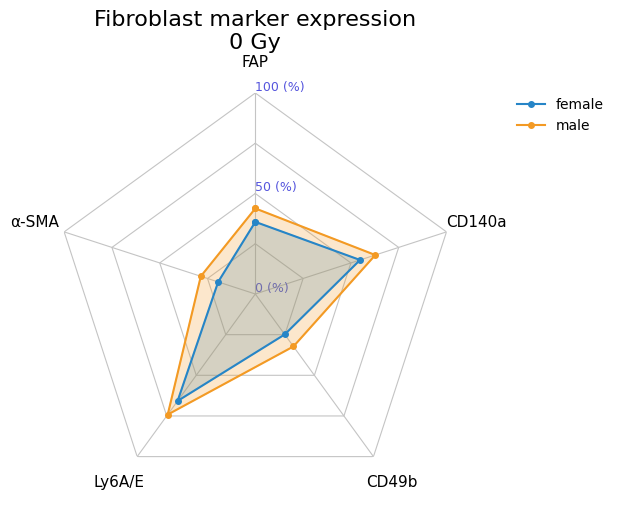

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "DejaVu Sans"

# CSV und Skript im selben Ordner ablegen.
df = pd.read_csv("/home/tom/Downloads/synthetic_facs_0Gy.csv")
markers = ["FAP", "CD140a", "CD49b", "Ly6AE", "alphaSMA"]
labels = ["FAP", "CD140a", "CD49b", "Ly6A/E", "α-SMA"]
means = df.loc[df["dose_Gy"].eq(0)].groupby("sex")[markers].mean()

angles = np.linspace(0, 2 * np.pi, len(markers), endpoint=False)
a = np.r_[angles, angles[0]]
fig, ax = plt.subplots(figsize=(7, 6), subplot_kw={"projection": "polar"})
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_ylim(0, 100)

# Polygonales Gitternetz statt kreisförmiger Ringe.
ax.grid(False)
ax.spines["polar"].set_visible(False)
for radius in [25, 50, 75, 100]:
    ax.plot(a, np.full(len(a), radius), color="#c4c4c4", lw=0.8, zorder=0)
for angle in angles:
    ax.plot([angle, angle], [0, 100], color="#c4c4c4", lw=0.8, zorder=0)

ax.set_xticks(angles)
ax.set_xticklabels(labels, fontsize=11)
ax.tick_params(axis="x", pad=12)
ax.set_yticks([0, 50, 100])
ax.set_yticklabels(["0 (%)", "50 (%)", "100 (%)"], color="#5555dd", fontsize=9)
ax.set_rlabel_position(0)

for sex, color in [("female", "#2685c7"), ("male", "#f39a24")]:
    values = means.loc[sex].to_numpy(dtype=float)
    v = np.r_[values, values[0]]
    ax.fill(a, v, color=color, alpha=0.23, zorder=2)
    ax.plot(a, v, color=color, lw=1.5, marker="o", markersize=4,
            label=sex, zorder=3)

ax.set_title("Fibroblast marker expression\n0 Gy", fontsize=16, pad=32)
ax.legend(loc="upper left", bbox_to_anchor=(1.12, 1.02), frameon=False)
fig.subplots_adjust(left=0.12, right=0.76, top=0.79, bottom=0.12)
fig.savefig("radar_0Gy.png", dpi=300, bbox_inches="tight")
fig.savefig("radar_0Gy.svg", bbox_inches="tight")
plt.show()